## Matched upper-bound sensitivity: WERM+CV and WERM+P

Paper figures 15. Saved results are shown by default; enable the switches below to recompute.

In [1]:
from pathlib import Path
import os
if not Path("WERM").is_dir() and Path("../WERM").is_dir():
    os.chdir("..")
assert Path("WERM").is_dir(), "Open this notebook from the repository root."
from paper_support import show_panels
RUN_EXPERIMENTS = False
REGENERATE_FIGURES = False
REGENERATE_FIGURES = REGENERATE_FIGURES or RUN_EXPERIMENTS

if REGENERATE_FIGURES:
    import numpy as np, pickle, time, logging
    import matplotlib.pyplot as plt
    from IPython.display import display
    main_logger = logging.getLogger("paper")
    Path("figures").mkdir(exist_ok=True)


In [2]:
if RUN_EXPERIMENTS:
    import os
    for key in ('OPENBLAS_NUM_THREADS', 'OMP_NUM_THREADS', 'MKL_NUM_THREADS'):
        os.environ[key] = '1'
    import pickle
    from pathlib import Path
    import numpy as np
    import pandas as pd
    from IPython.display import display
    from tools import el_matched_selection as matched
    (MATCH_ROOT, MATCH_SPEC, MATCH_WEIGHTS) = matched.prepare(trials=100, theory_draws=20, frozen_weights='results/E_L_matched_CV_penalty/3af038cb5e34/weights.pkl')
    MATCH_FILE = MATCH_ROOT / 'study.pkl'
    MATCH_STUDY = pickle.loads(MATCH_FILE.read_bytes()) if MATCH_FILE.exists() else matched.run(MATCH_ROOT, MATCH_SPEC, MATCH_WEIGHTS, jobs=int(os.environ.get('EL_MATCHED_JOBS', '12')))
    MATCH_SUMMARY = matched.summary(MATCH_STUDY)
    display(MATCH_SUMMARY.round(5))


### Joint comparison with penalty Theory

In [3]:
if REGENERATE_FIGURES:
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.patches import Patch
    from pathlib import Path
    import tools.consistent_plotting as match_style
    if not RUN_EXPERIMENTS:
        MATCH_ROOT = Path('results/E_L_matched_CV_penalty/3af038cb5e34')
    match_style.OUTPUT_DIR = MATCH_ROOT / 'figures'
    match_style.SOURCE_HASHES.clear()
    match_style.FIGURE_AUDIT.clear()
    MATCH_SAVED = match_style.load_saved(MATCH_ROOT / 'study.pkl')
    MATCH_SPEC = MATCH_SAVED['specification']
    MATCH_RECORDS = MATCH_SAVED['records']
    MATCH_BOUNDS = np.arange(1, 7)
    MATCH_METHODS = ('cv', 'penalty')
    MATCH_LABELS = ('\\textbf{WERM+CV}', '\\textbf{WERM+P}')
    MATCH_COLORS = ('black', '#AA3377')

    def matched_groups(method, metric):
        return [np.array([fit[metric] for r in MATCH_RECORDS for fit in (r['fits'][L]['theory'] if method == 'theory' else [r['fits'][L][method]])]) for L in MATCH_BOUNDS]
    for (metric, ylabel) in [('count', 'No. change points'), ('haus', 'Hausdorff dist. / $n$')]:
        for kind in ('line',):
            with plt.rc_context(match_style.CANONICAL_STYLE if kind == 'line' else match_style.PAPER_STYLE):
                if kind == 'line':
                    (fig, ax) = plt.subplots(figsize=(5, 4))
                    fig._canonical_m1 = True
                else:
                    (fig, ax) = match_style.paper_panel()
                    rng = np.random.default_rng(42)
                for (j, method) in enumerate(MATCH_METHODS):
                    groups = matched_groups(method, metric)
                    if kind == 'line':
                        match_style.error_series(ax, MATCH_BOUNDS, groups, MATCH_LABELS[j], MATCH_COLORS[j], ('D', 'o')[j], ('-', '--')[j], scale=1)
                    else:
                        for (i, values) in enumerate(groups):
                            match_style.box_group(ax, values, 3 * i + j, MATCH_COLORS[j], rng)
                ax.set(xlabel='$L$', ylabel=ylabel)
                if kind == 'line':
                    theory = matched_groups('theory', metric)
                    means = [np.mean(v[np.isfinite(v)]) if np.isfinite(v).any() else np.nan for v in theory]
                    theory_label = '\\textbf{Theory}'
                    ax.scatter(MATCH_BOUNDS, means, label=theory_label, marker='d', color='#4477AA', s=120, edgecolor='white', linewidth=2.5, alpha=0.99, zorder=5)
                    ax.set_xticks(MATCH_BOUNDS)
                    (handles, labels) = ax.get_legend_handles_labels()
                    ordered = (*MATCH_LABELS, theory_label)
                    if metric == 'count':
                        ax.legend([handles[labels.index(label)] for label in ordered], ordered, loc='best', prop={'size': 14}, framealpha=0.4)
                else:
                    ax.set_xticks(np.arange(len(MATCH_BOUNDS)) * 3 + 0.5, [str(v) for v in MATCH_BOUNDS])
                    if metric == 'count':
                        ax.legend(handles=[Patch(facecolor=c, alpha=0.28, edgecolor='black', label=l) for (c, l) in zip(MATCH_COLORS, MATCH_LABELS)], loc='best', fontsize=7)
                if metric == 'count':
                    ax.axhline(3, color='gray', lw=2.5 if kind == 'line' else 1.4, alpha=0.8, zorder=0)
                    ax.set_yticks(range(6))
                if kind == 'line':
                    fig.tight_layout()
                match_style.export_plot(fig, f'matched_upper_L_{metric}_{kind}')
    MATCH_HIST_BOUNDS = (3, 6)
    MATCH_POOLS = [[np.concatenate([np.asarray(r['fits'][L][method]['cp']) / MATCH_SPEC['n'] for r in MATCH_RECORDS]) for method in MATCH_METHODS] for L in MATCH_HIST_BOUNDS]
    match_style.histogram_grid(MATCH_POOLS, MATCH_LABELS, MATCH_COLORS, MATCH_SPEC['true_fractions'], 'matched_upper_L_histograms_L3_L6', row_labels=[f'$L={L}$' for L in MATCH_HIST_BOUNDS], density_label_x=0.005, figsize=(5, 4))
    match_style.verify_sources()
    plt.close("all")


## Matched rerun: true locations $(0.35,0.6,0.75)n$, separation $\Delta_n=n/20$

In [4]:
if RUN_EXPERIMENTS:
    import os
    for key in ('OPENBLAS_NUM_THREADS', 'OMP_NUM_THREADS', 'MKL_NUM_THREADS'):
        os.environ[key] = '1'
    import pickle
    from pathlib import Path
    import numpy as np
    from IPython.display import display
    from tools import el_matched_selection as gapb_matched
    (GAPB_ROOT, GAPB_SPEC, GAPB_WEIGHTS) = gapb_matched.prepare(trials=100, theory_draws=20, true_fractions=(0.35, 0.6, 0.75), delta_fraction=0.05, frozen_weights='results/E_L_matched_CV_penalty/e072dcb13421/weights.pkl')
    GAPB_FILE = GAPB_ROOT / 'study.pkl'
    GAPB_STUDY = pickle.loads(GAPB_FILE.read_bytes()) if GAPB_FILE.exists() else gapb_matched.run(GAPB_ROOT, GAPB_SPEC, GAPB_WEIGHTS, jobs=int(os.environ.get('EL_GAP20_JOBS', '24')))
    GAPB_SUMMARY = gapb_matched.summary(GAPB_STUDY)
    display(GAPB_SUMMARY.round(5))


In [5]:
if REGENERATE_FIGURES:
    from pathlib import Path
    import hashlib
    import numpy as np
    import matplotlib.pyplot as plt
    import tools.consistent_plotting as gapb_style
    if not RUN_EXPERIMENTS:
        GAPB_ROOT = Path('results/E_L_matched_CV_penalty/e072dcb13421')
    gapb_style.OUTPUT_DIR = GAPB_ROOT / 'figures'
    gapb_style.SOURCE_HASHES.clear()
    gapb_style.FIGURE_AUDIT.clear()
    GAPB_SAVED = gapb_style.load_saved(GAPB_ROOT / 'study.pkl')
    GAPB_SPEC = GAPB_SAVED['specification']
    GAPB_RECORDS = GAPB_SAVED['records']
    GAPB_BOUNDS = np.arange(1, 7)
    GAPB_METHODS = ('cv', 'penalty')
    GAPB_LABELS = ('\\textbf{WERM+CV}', '\\textbf{WERM+P}')
    GAPB_COLORS = ('black', '#AA3377')
    GAPB_THEORY = '\\textbf{Theory}'

    def gapb_groups(method, metric):
        return [np.array([fit[metric] for r in GAPB_RECORDS for fit in (r['fits'][L]['theory'] if method == 'theory' else [r['fits'][L][method]])]) for L in GAPB_BOUNDS]

    def gapb_panel(ax, metric):
        for (j, method) in enumerate(GAPB_METHODS):
            gapb_style.error_series(ax, GAPB_BOUNDS, gapb_groups(method, metric), GAPB_LABELS[j], GAPB_COLORS[j], ('D', 'o')[j], ('-', '--')[j], scale=1)
        values = gapb_groups('theory', metric)
        means = [np.mean(v[np.isfinite(v)]) if np.isfinite(v).any() else np.nan for v in values]
        ax.scatter(GAPB_BOUNDS, means, label=GAPB_THEORY, marker='d', color='#4477AA', s=120, edgecolor='white', linewidth=2.5, alpha=0.99, zorder=5)
        ax.set(xlabel='$L$', ylabel='No. change points' if metric == 'count' else 'Hausdorff dist. / $n$', xticks=GAPB_BOUNDS)
        if metric == 'count':
            ax.axhline(3, color='gray', lw=2.5, alpha=0.8, zorder=0)
            ax.set_yticks(range(6))
            (handles, labels) = ax.get_legend_handles_labels()
            ordered = (*GAPB_LABELS, GAPB_THEORY)
            ax.legend([handles[labels.index(label)] for label in ordered], ordered, loc='best', prop={'size': 14}, framealpha=0.4)
    for metric in ('haus', 'count'):
        with plt.rc_context(gapb_style.CANONICAL_STYLE):
            (fig, ax) = plt.subplots(figsize=(5, 4))
            fig._canonical_m1 = True
            gapb_panel(ax, metric)
            fig.tight_layout()
            gapb_style.export_plot(fig, f'gapb_upper_L_{metric}_line')
    GAPB_HIST_BOUNDS = (3, 6)
    GAPB_POOLS = [[np.concatenate([np.asarray(r['fits'][L][method]['cp']) / GAPB_SPEC['n'] for r in GAPB_RECORDS]) for method in GAPB_METHODS] for L in GAPB_HIST_BOUNDS]
    from sklearn.neighbors import KernelDensity
    from sklearn.model_selection import GridSearchCV
    GAPB_PEAK = 0.0
    for row in GAPB_POOLS:
        for pooled in row:
            values = gapb_style.clean(pooled)
            if not len(values):
                continue
            GAPB_PEAK = max(GAPB_PEAK, float(np.histogram(values, bins=12, density=True)[0].max()))
            if len(values) > 6:
                cache_key = hashlib.sha256(values.tobytes()).hexdigest()
                if cache_key not in gapb_style.KDE_CACHE:
                    kde_cv = GridSearchCV(KernelDensity(kernel='gaussian'), {'bandwidth': np.logspace(-2, 0, 50)}, cv=5, n_jobs=1)
                    kde_cv.fit(values.reshape(-1, 1))
                    kde_x = np.linspace(0, 1, 200)
                    kde_y = np.exp(kde_cv.best_estimator_.score_samples(kde_x.reshape(-1, 1)))
                    gapb_style.KDE_CACHE[cache_key] = (kde_x, kde_y)
                GAPB_PEAK = max(GAPB_PEAK, float(gapb_style.KDE_CACHE[cache_key][1].max()))
    GAPB_DENSITY_LIMIT = max(20.0, 5.0 * np.ceil(GAPB_PEAK / 5.0))
    GAPB_ORIGINAL_EXPORT = gapb_style.export_plot

    def gapb_histogram_export(fig, name, description=''):
        for ax in fig.axes:
            ax.set_xticks(GAPB_SPEC['true_fractions'], [f'${cp:g}$' for cp in GAPB_SPEC['true_fractions']])
            ax.set_yticks([0, 0.4 * GAPB_DENSITY_LIMIT, 0.8 * GAPB_DENSITY_LIMIT])
            ax.tick_params(labelsize=12)
        return GAPB_ORIGINAL_EXPORT(fig, name, description)
    try:
        gapb_style.export_plot = gapb_histogram_export
        gapb_style.histogram_grid(GAPB_POOLS, GAPB_LABELS, GAPB_COLORS, GAPB_SPEC['true_fractions'], 'gapb_upper_L_histograms_L3_L6', row_labels=[f'$L={L}$' for L in GAPB_HIST_BOUNDS], density_label_x=0.005, figsize=(5, 4), density_limit=GAPB_DENSITY_LIMIT)
    finally:
        gapb_style.export_plot = GAPB_ORIGINAL_EXPORT
    gapb_style.verify_sources()
    plt.close("all")


## Figure 15

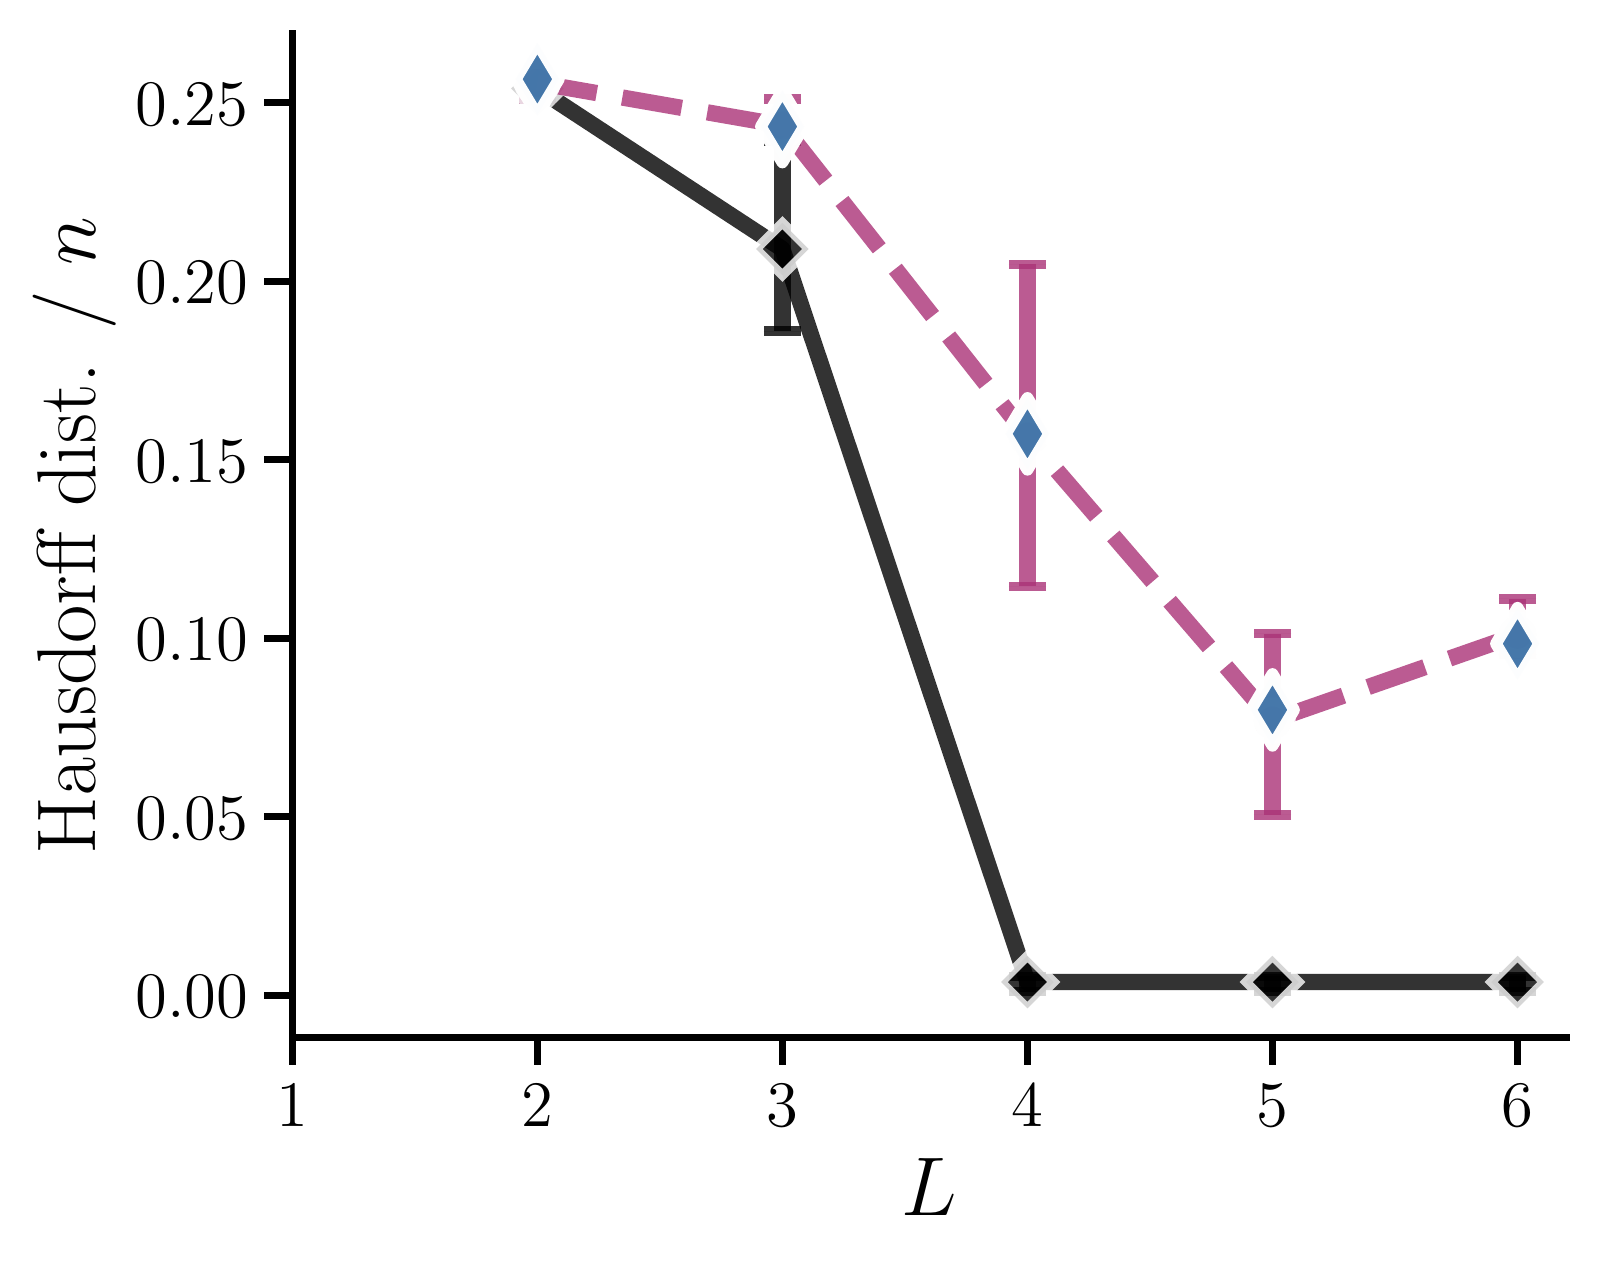

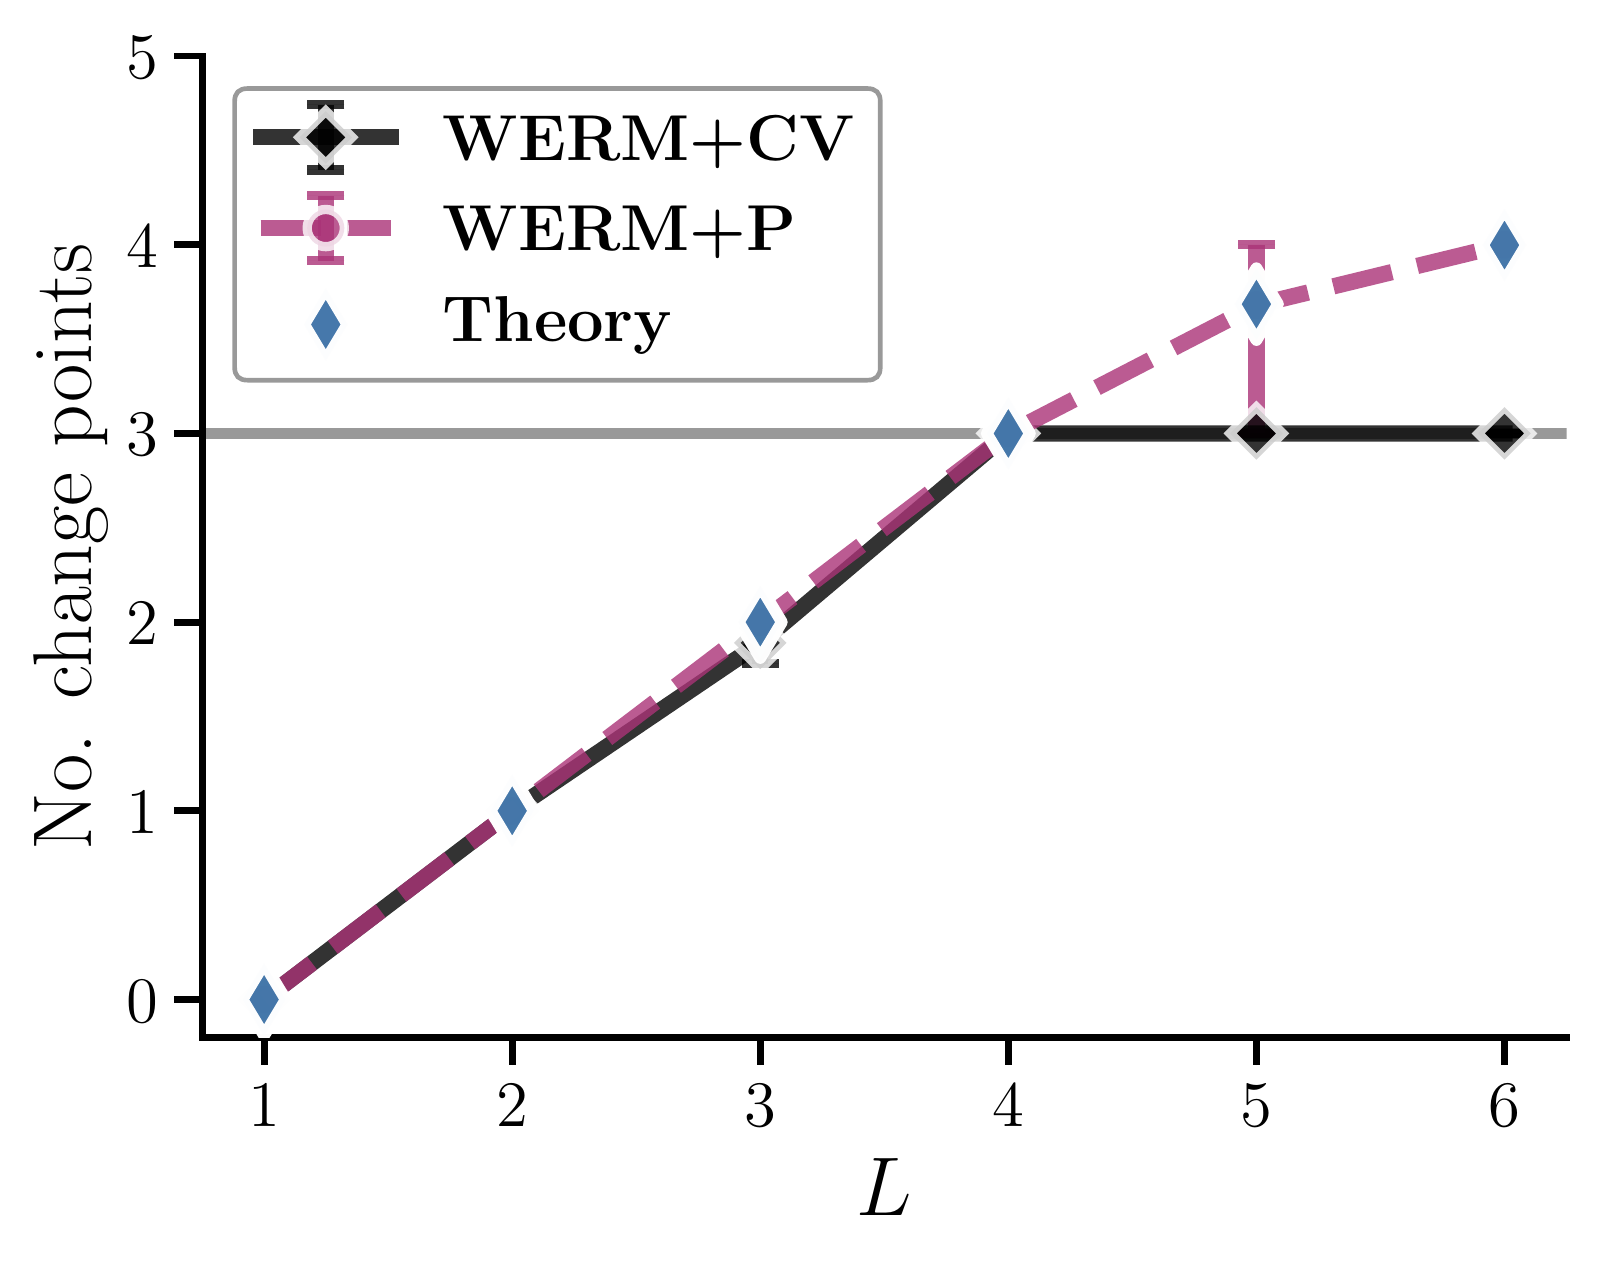

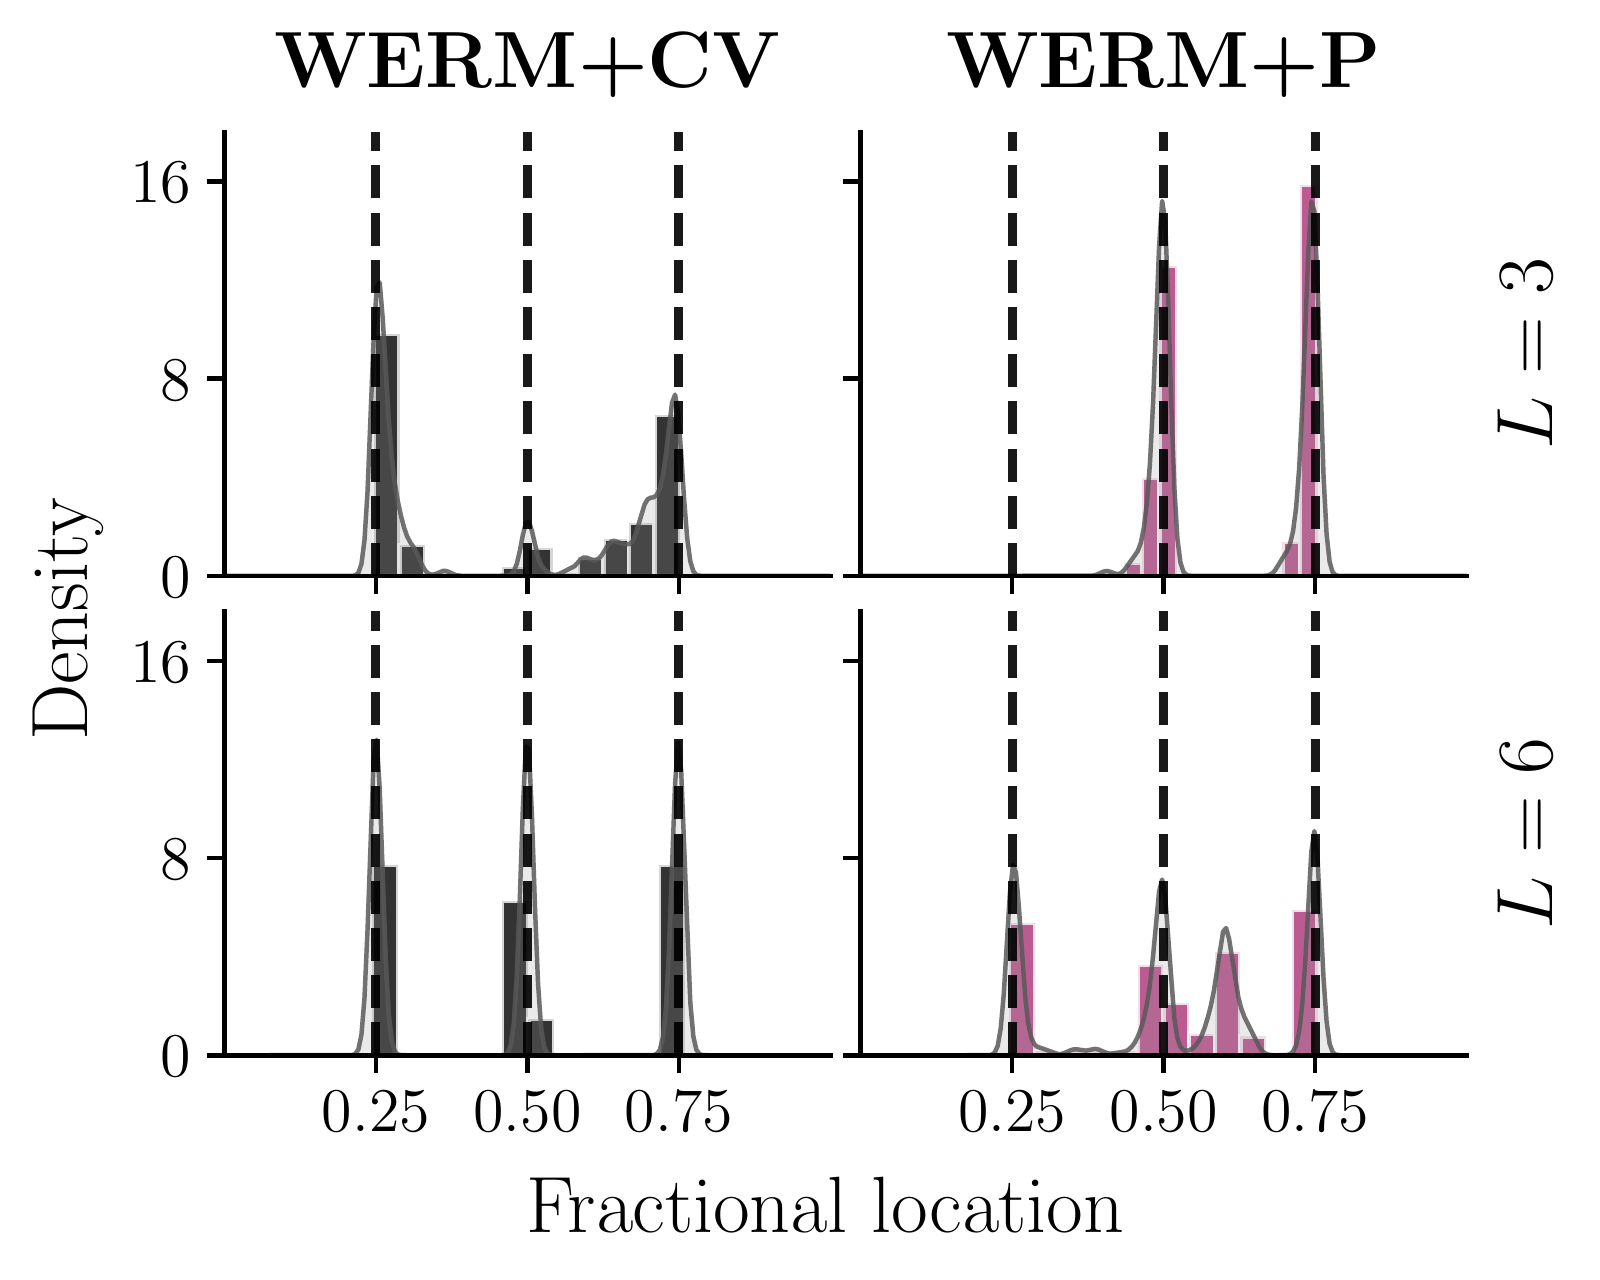

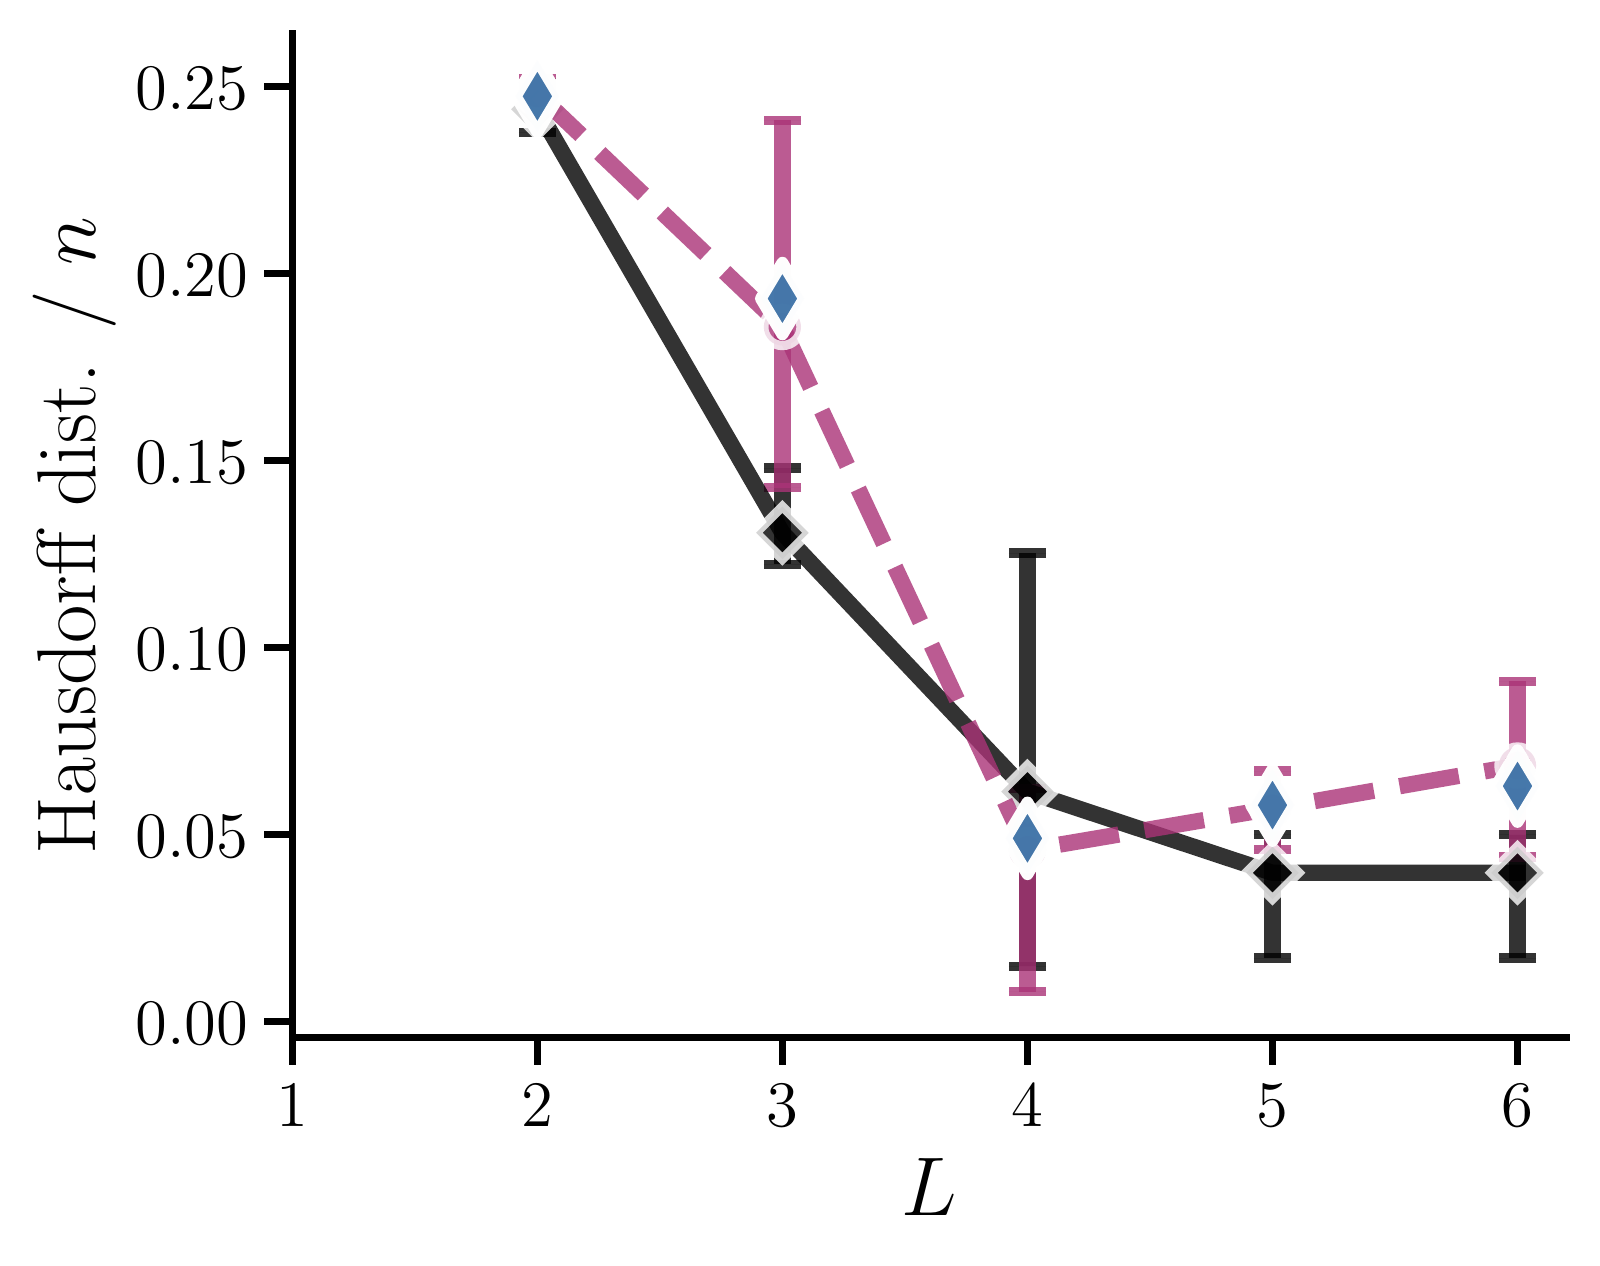

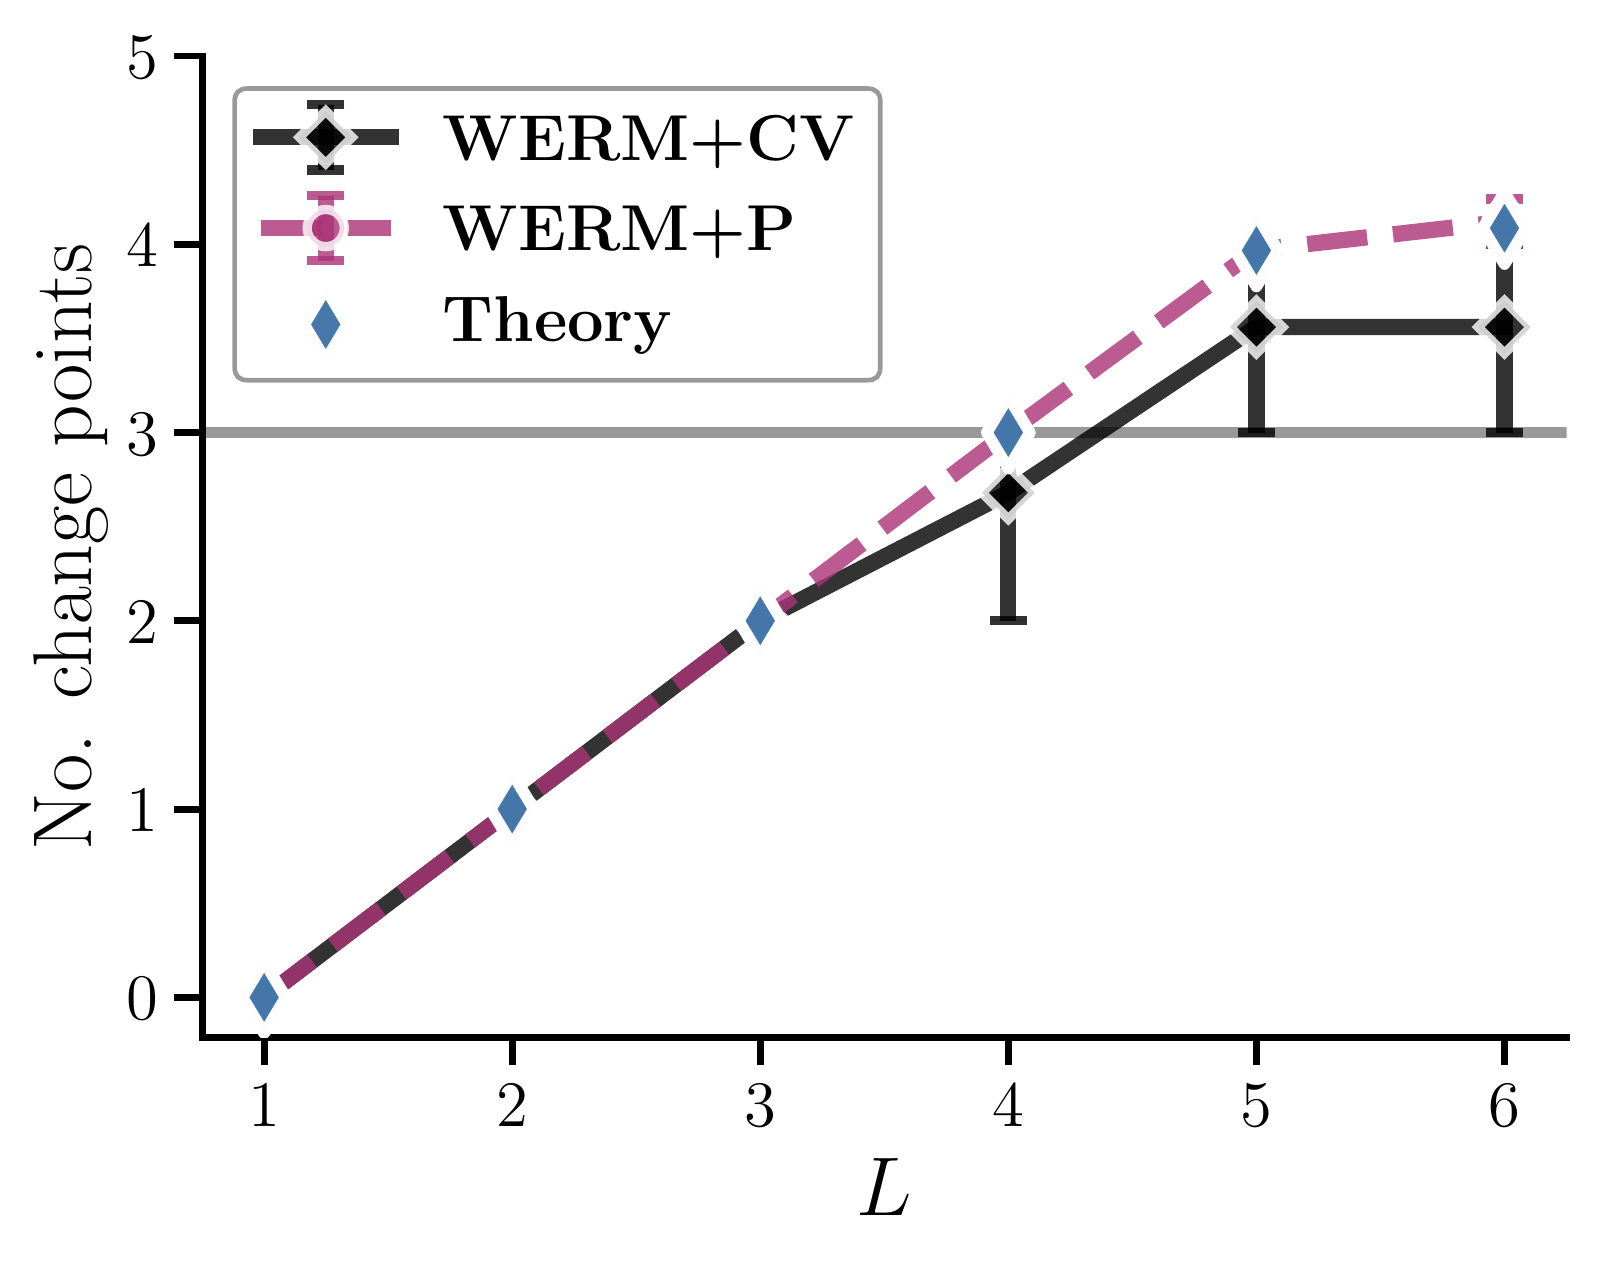

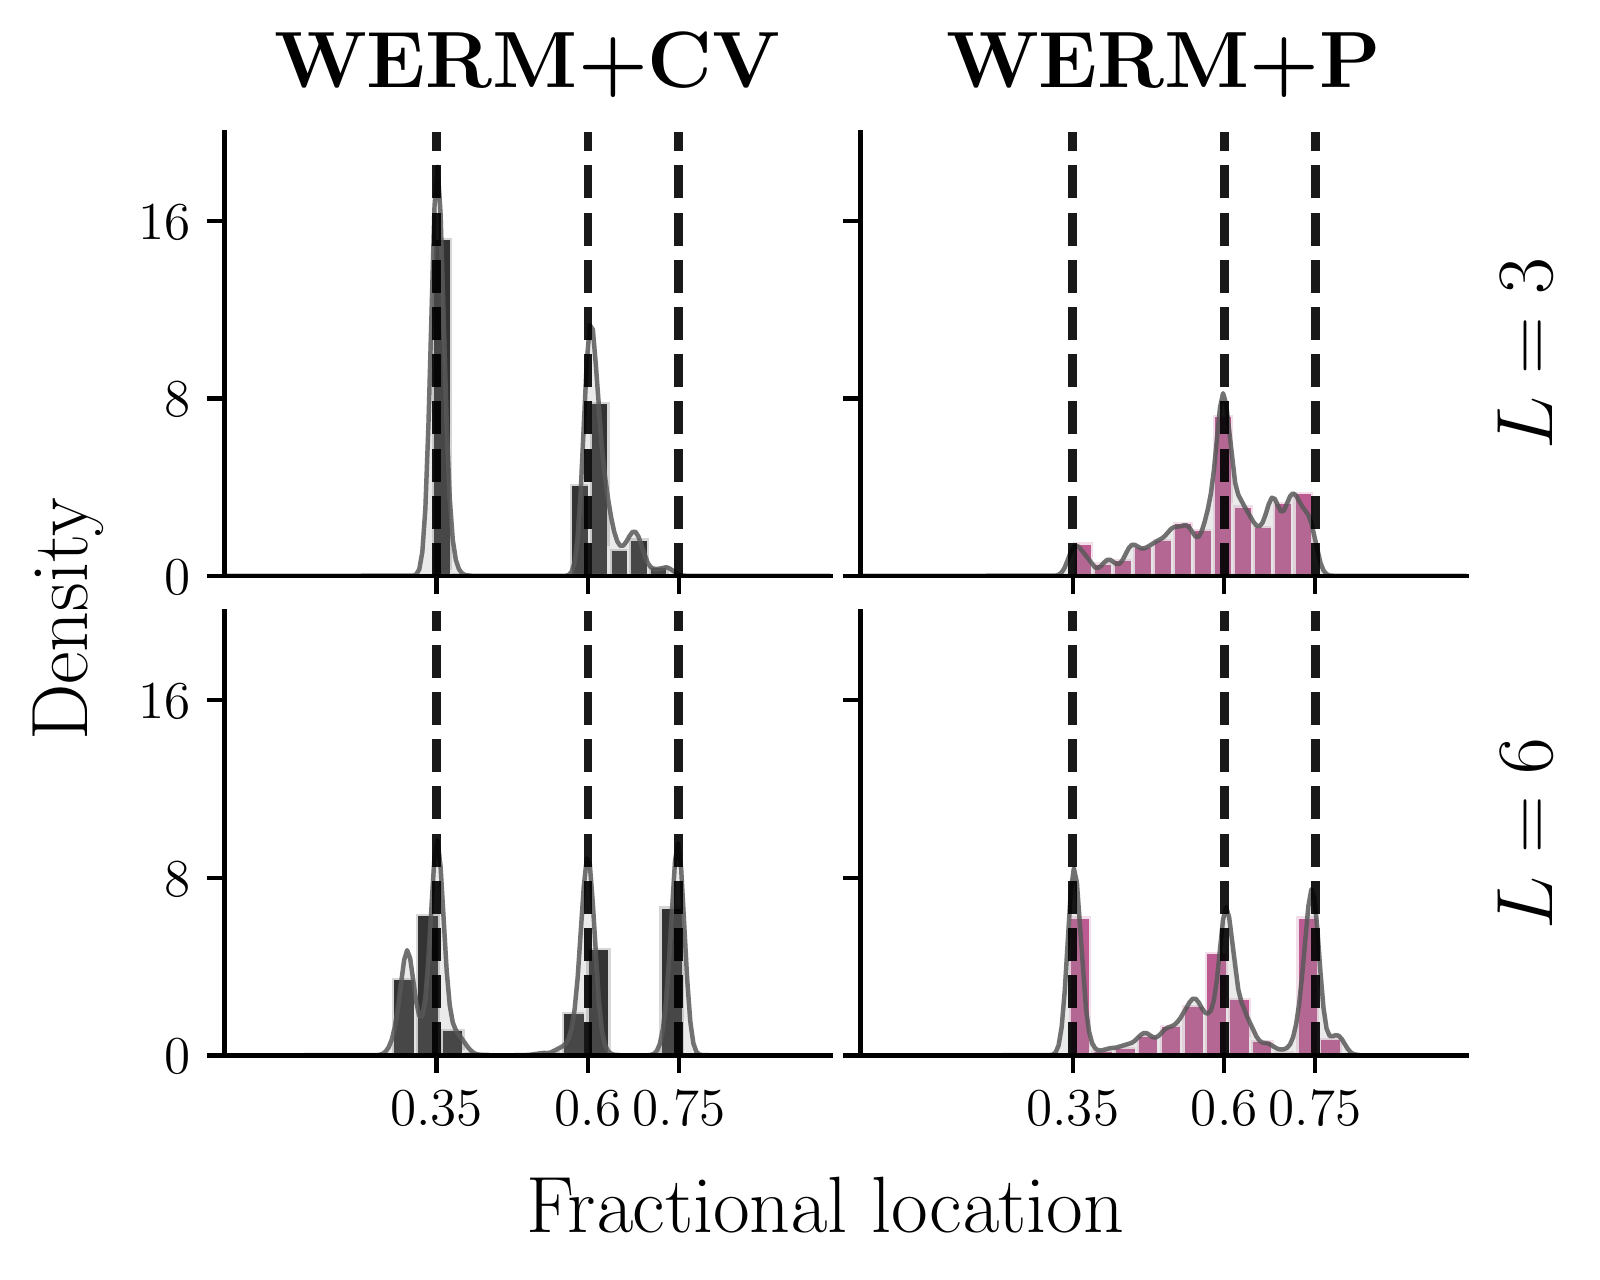

In [6]:
panels = [folder / 'figures' / f'{prefix}_upper_L_{metric}.pdf' for folder, prefix in [(MATCH_ROOT, 'matched'), (GAPB_ROOT, 'gapb')] for metric in ['haus_line', 'count_line', 'histograms_L3_L6']] if REGENERATE_FIGURES else ['figures/figure_15/panel_01.pdf', 'figures/figure_15/panel_02.pdf', 'figures/figure_15/panel_03.pdf', 'figures/figure_15/panel_04.pdf', 'figures/figure_15/panel_05.pdf', 'figures/figure_15/panel_06.pdf']
show_panels(panels)
